## 数据加载与探索性分析

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 读取数据集
ratings = pd.read_csv('ml-latest-small/ratings.csv')
movies = pd.read_csv('ml-latest-small/movies.csv')

# 查看数据基本信息
print("========== 评分数据概览 ==========")
print(f"评分记录数：{ratings.shape[0]}")
print(f"用户数量：  {ratings['userId'].nunique()}")
print(f"电影数量：  {ratings['movieId'].nunique()}")
print(f"评分均值：  {ratings['rating'].mean():.2f}")
print(f"评分稀疏度："f"{100-100*len(ratings)/(ratings['userId'].nunique()* # 1-(实际影评数/所有用户数*电影数)
       ratings['movieId'].nunique()):.2f}%")

========== 评分数据概览 ==========
评分记录数：100836
用户数量：  610
电影数量：  9724
评分均值：  3.50
评分稀疏度：98.30%


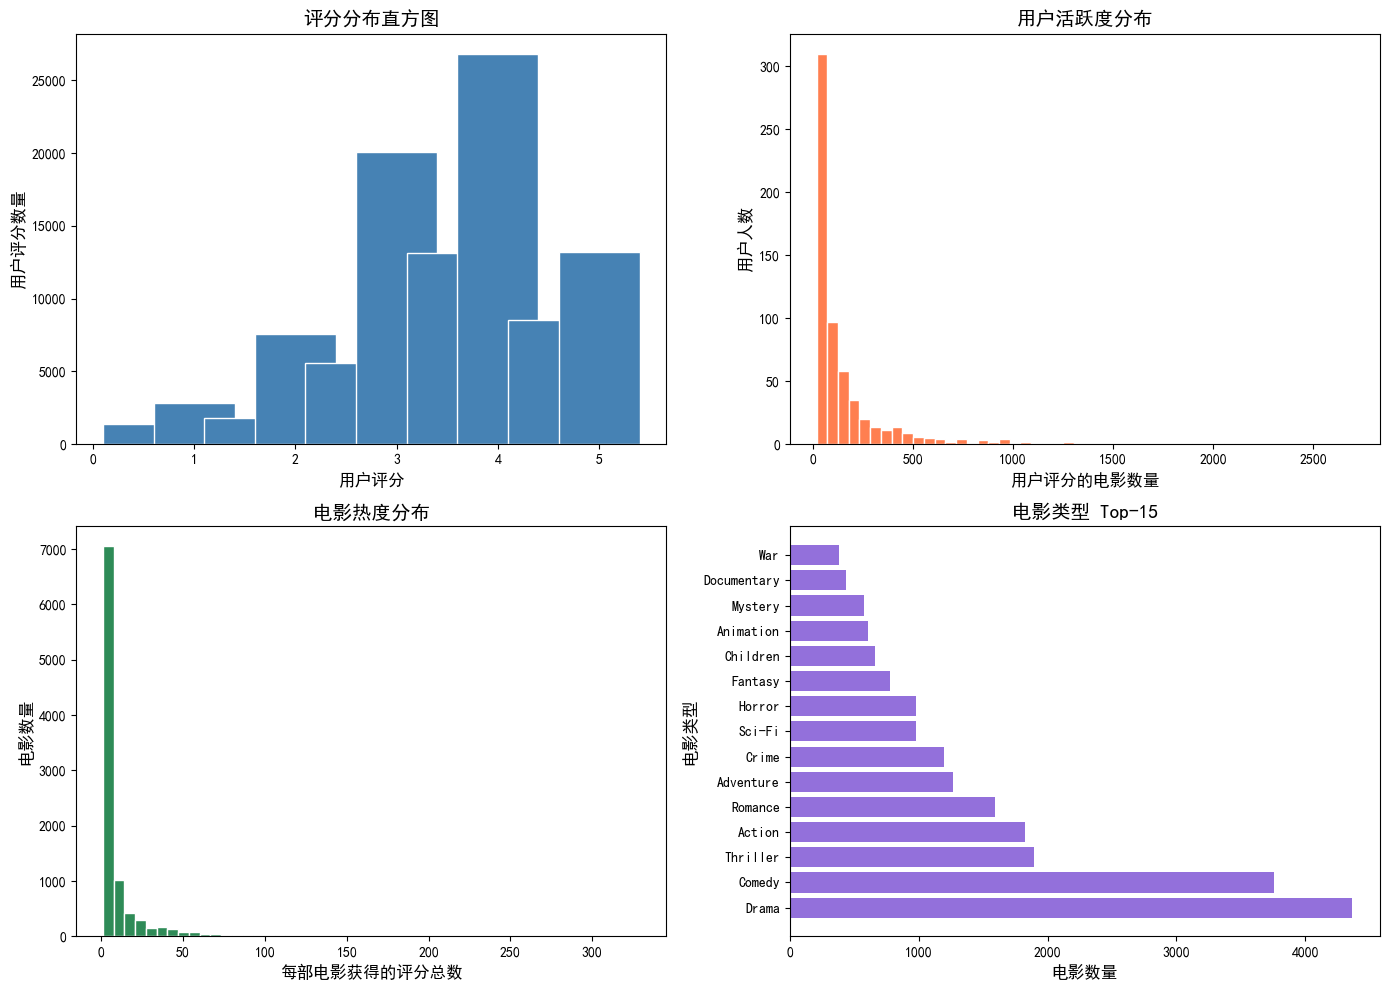

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10)) # 创建一个 2行 × 2列 的画布。axes[x, y]代表第x行第y列

# 子图1：评分分布直方图
rating_counts = ratings['rating'].value_counts().sort_index() # 获取rating列中 频次统计 并将数据从高到低排列
axes[0, 0].bar(rating_counts.index, rating_counts.values,     # 画纵向柱状图，index做x轴数据, values做y轴数据
               color='steelblue', edgecolor='white')          # 设置柱子填充为蓝色，边缘为白色
axes[0, 0].set_title('评分分布直方图', fontsize=14)
axes[0, 0].set_xlabel('用户评分', fontsize=12)
axes[0, 0].set_ylabel('用户评分数量', fontsize=12)

# 子图2：用户活跃度分布
user_rating_counts = ratings.groupby('userId').size()         # 根据用户ID分组将所有属于相同用户的数据聚合，统计每组数据
axes[0, 1].hist(user_rating_counts, bins=50,                  # 画直方图，传入统计结果，将用户评分数量切分50等距区间
                color='coral', edgecolor='white')
axes[0, 1].set_title('用户活跃度分布', fontsize=14)
axes[0, 1].set_xlabel('用户评分的电影数量', fontsize=12)
axes[0, 1].set_ylabel('用户人数', fontsize=12)

# 子图3：电影热度分布
movie_rating_counts = ratings.groupby('movieId').size()       # 根据电影ID分组将所有属于相同电影的数据聚合，统计每组数据
axes[1, 0].hist(movie_rating_counts, bins=50,                 # 画直方图，传入统计结果，将数量切分50等距区间
                color='seagreen', edgecolor='white')
axes[1, 0].set_title('电影热度分布', fontsize=14)
axes[1, 0].set_xlabel('每部电影获得的评分总数', fontsize=12)
axes[1, 0].set_ylabel('电影数量', fontsize=12)

# 子图4：电影类型 Top-15 统计（使用 Counter）
from collections import Counter
genre_counter = Counter()
for genres_str in movies['genres']:
    for genre in genres_str.split('|'):
        if genre != '(no genres listed)':
            genre_counter[genre] += 1
top_genres = genre_counter.most_common(15)             # 将计数器里所有的类型按出现次数从高到低排序，只取前15个
genres_name, genres_count = zip(*top_genres)           # *将top_genres列表拆成15个独立元组参数，zip多元组按位置配对
axes[1, 1].barh(range(len(genres_name)), genres_count, # 画水平条形图
                color='mediumpurple')
axes[1, 1].set_title('电影类型 Top-15', fontsize=14)
axes[1, 1].set_xlabel('电影数量', fontsize=12)
axes[1, 1].set_ylabel('电影类型', fontsize=12)
axes[1, 1].set_yticks(range(len(genres_name)))  
axes[1, 1].set_yticklabels(genres_name)        

plt.tight_layout()
plt.savefig('eda_visualization.png', dpi=150)
plt.show()

评分矩阵形状：(610, 9724)
用户相似度矩阵形状：(610, 610)


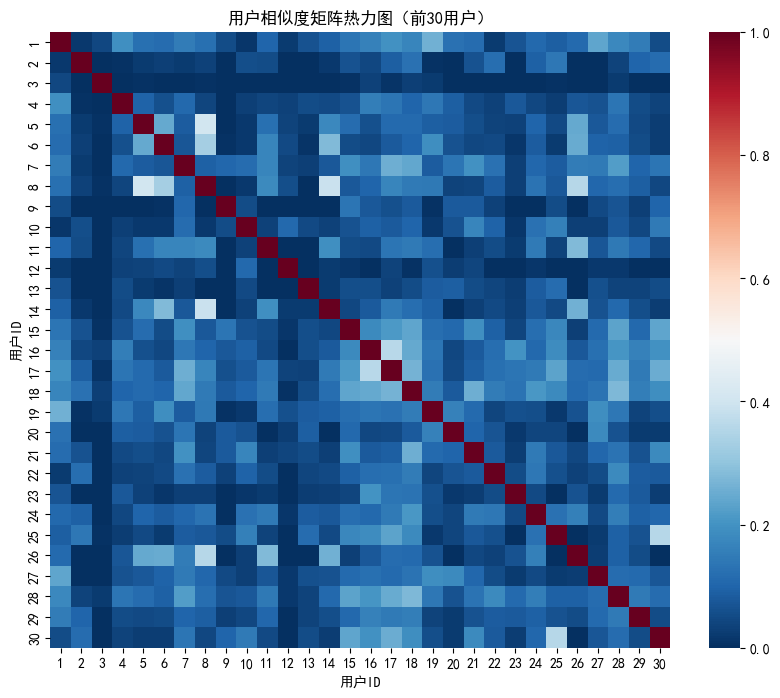

In [5]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
import seaborn as sns

# 构建评分矩阵（行=用户，列=电影，值=评分）
rating_matrix = ratings.pivot_table(
    index='userId', columns='movieId', values='rating') # userId作为行，columns作为列，将rating列的值匹配对应行对应列的值
print(f"评分矩阵形状：{rating_matrix.shape}")

# 划分训练集（80%）和测试集（20%）
train_data = ratings.sample(frac=0.8, random_state=0) # 抽取比例0.8，固定种子为0
test_data = ratings.drop(train_data.index) # 删除原矩阵所抽取行的索引

# 构建训练矩阵，未评分填充 0
train_matrix = train_data.pivot_table(
    index='userId', columns='movieId', values='rating'
).fillna(0) # 数据重铸为矩阵，并填缺失值为0

# 计算用户-用户余弦相似度矩阵
user_similarity = cosine_similarity(train_matrix.values)
user_similarity_df = pd.DataFrame(
    user_similarity,
    index=train_matrix.index,
    columns=train_matrix.index
)
print(f"用户相似度矩阵形状：{user_similarity_df.shape}")

# 截取前 30 个用户的相似度子矩阵
sample_sim = user_similarity_df.iloc[:30, :30]

plt.figure(figsize=(10, 8))
sns.heatmap(sample_sim,
            cmap='RdBu_r',         # 红蓝渐变，数值高为红色，低为蓝色
            annot=False,
            cbar=True,
            xticklabels=True,
            yticklabels=True)
plt.title('用户相似度矩阵热力图（前30用户）')
plt.xlabel('用户ID')
plt.ylabel('用户ID')
plt.show()

In [6]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

def predict_rating_knn(user_id, movie_id, train_matrix, user_sim_df, k=20):
    """基于 KNN 预测用户对电影的评分"""
    if (user_id not in train_matrix.index or
        movie_id not in train_matrix.columns): # 找不到对应的用户ID或者电影ID
        return train_matrix.values[train_matrix.values > 0].mean()  # 取训练矩阵所有不为空的值取平均作为其值

    rated_users = train_matrix[movie_id][train_matrix[movie_id] > 0].index # 布尔过滤，保留值大于零的条目的索引标签
    if len(rated_users) == 0: # 没有任何用户评分过这部电影
        return train_matrix.values[train_matrix.values > 0].mean() # 返回全局平均评分

    sim_scores = user_sim_df.loc[user_id, rated_users] # 筛选出输入的主要用户，还有评分过的相同用户
    sim_scores = sim_scores.sort_values(ascending=False) # 将用户评分从大到小排序
    top_k_users = sim_scores.head(k) # 筛选出前k个相似度最高的

    # 加权平均：pred = sum(sim * rating) / sum(|sim|)
    ratings_sum, sim_sum = 0, 0 # ratings_sum 相似度 × 评分 sim_sum相似度的绝对值
    for neighbor_id, sim in top_k_users.items():
        neighbor_rating = train_matrix.loc[neighbor_id, movie_id] # 找出训练矩阵中该邻居对电影id的真实评分
        ratings_sum += sim * neighbor_rating # 相似度越高的邻居，其评分在最终结果中的影响权重越大
        sim_sum += abs(sim) # 累加相似度的绝对值

    # 如果相似度综合>0则返回加权平均值。若权重总和为0函数返回全局平均评分
    return ratings_sum / sim_sum if sim_sum > 0 else \
           train_matrix.values[train_matrix.values > 0].mean()

# 在测试集上评估
predictions, actuals = [], []
for _, row in test_data.head(500).iterrows(): # 截取测试集的前500行
    pred = predict_rating_knn(
        row['userId'], row['movieId'],
        train_matrix, user_similarity_df, k=20)
    predictions.append(pred)
    actuals.append(row['rating'])

rmse = np.sqrt(mean_squared_error(actuals, predictions)) # 均方根误差
mae = mean_absolute_error(actuals, predictions) # 
print(f"KNN 协同过滤: 均方根误差={rmse:.4f}, 平均绝对误差={mae:.4f}")

KNN 协同过滤: 均方根误差=0.9895, 平均绝对误差=0.7577


In [9]:
from surprise import SVD, Reader, Dataset
from surprise.model_selection import cross_validate

reader = Reader(rating_scale=(0.5, 5.0)) # 评分的最小值是 0.5，最大值是 5.0
data = Dataset.load_from_df(
    ratings[['userId', 'movieId', 'rating']], reader)

# SVD 模型：50 维隐因子，20 轮迭代
svd = SVD(n_factors=50, n_epochs=20,
          lr_all=0.005, reg_all=0.02, random_state=0) # 隐因子数量K=50，迭代优化20次，学习率，正规化系数，固定种子

# 5 折交叉验证
cv_results = cross_validate(
    svd, data, measures=['RMSE', 'MAE'], cv=5, verbose=False) # measures=['RMSE', 'MAE'] 每轮自动计算这两个误差指标。

print(f"SVD 平均 均方根误差: {cv_results['test_rmse'].mean():.4f}"
      f" +/- {cv_results['test_rmse'].std():.4f}")
print(f"SVD 平均 绝对误差:  {cv_results['test_mae'].mean():.4f}"
      f" +/- {cv_results['test_mae'].std():.4f}")

SVD 平均 均方根误差: 0.8713 +/- 0.0017
SVD 平均 绝对误差:  0.6694 +/- 0.0021


In [13]:
trainset = data.build_full_trainset()

final_svd = SVD(
    n_factors=50,
    n_epochs=20,
    lr_all=0.005,
    reg_all=0.02,
    random_state=0
)

final_svd.fit(trainset)

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

# 电影类型 One-Hot 编码
genres_dummies = movies['genres'].str.get_dummies(sep='|') # 按竖线拆分字符串，将所有可能出现的电影类型作为新列。

# 计算电影-电影余弦相似度
movie_features = genres_dummies.values
movie_similarity = cosine_similarity(movie_features) # 计算电影 类型之间的余弦相似度
movie_similarity_df = pd.DataFrame(
    movie_similarity,
    index=movies['movieId'],
    columns=movies['movieId']
) # 将纯数组的行和列分别附上电影ID标签

def recommend_by_content(movie_id, movies_df, sim_df, top_n=10):
    """基于内容的电影推荐"""
    sim_scores = sim_df.loc[movie_id].sort_values(
        ascending=False) # 从电影-电影余弦相似度方阵取出对应电影ID的那一条向量，将相似度从高到低排序
    sim_scores = sim_scores[sim_scores.index != movie_id] # 删除相似度为1.0的自匹配项
    top_movies = sim_scores.head(top_n) # 截取前n个相似度最高的最近邻
    result = pd.DataFrame({
        'movieId': top_movies.index,
        'similarity': top_movies.values
    }) # 构建DataFrame
    return result.merge(
        movies_df[['movieId', 'title', 'genres']],
        on='movieId', how='left') # 合并电影元数据（就是将电影ID和相似度矩阵合并名称、类型）

# 为 Toy Story (movieId=1) 推荐相似电影
recs = recommend_by_content(1, movies, movie_similarity_df)
print(recs[['title', 'genres', 'similarity']])

# 该方法较为粗糙，仅按题材分配

                                               title  \
0                                        Antz (1998)   
1                             Shrek the Third (2007)   
2  Asterix and the Vikings (Astérix et les Viking...   
3                   Emperor's New Groove, The (2000)   
4                           The Good Dinosaur (2015)   
5     Adventures of Rocky and Bullwinkle, The (2000)   
6                     Tale of Despereaux, The (2008)   
7                                 Toy Story 2 (1999)   
8                                       Turbo (2013)   
9                              Monsters, Inc. (2001)   

                                        genres  similarity  
0  Adventure|Animation|Children|Comedy|Fantasy         1.0  
1  Adventure|Animation|Children|Comedy|Fantasy         1.0  
2  Adventure|Animation|Children|Comedy|Fantasy         1.0  
3  Adventure|Animation|Children|Comedy|Fantasy         1.0  
4  Adventure|Animation|Children|Comedy|Fantasy         1.0  
5  Adventure|Anim

In [ ]:
def hybrid_recommend(user_id, movies_df, ratings_df,
                     content_sim_df, svd_model,
                     alpha=0.7, top_n=10):
    """混合推荐：加权融合 SVD + 内容相似度"""
    '''
    user_id	        要给哪个用户推荐
    movies_df	    电影信息表，比如 movieId, title, genres
    ratings_df	    用户评分表，比如 userId, movieId, rating
    content_sim_df	电影和电影之间的内容相似度矩阵
    svd_model	    训练好的 SVD 模型
    alpha	        SVD 分数占比，默认 0.7
    top_n	        推荐前多少部电影
    '''
    # 获取用户已评分电影
    rated_movie_ids = set(ratings_df[
        ratings_df['userId'] == user_id]['movieId']) # 找出用户已经看过的电影
    # 候选电影：热门且未评分的
    popular = ratings_df.groupby('movieId').size() # 生成一个pdSeries 装电影ID和被评分次数
    popular = popular[popular >= 10].index.tolist() # 找到popular出现十次以上的 提取索引 转化为列表
    candidates = [m for m in popular
                  if m not in rated_movie_ids] # 添加候选
    
    # SVD 协同过滤评分（标准化）
    svd_scores = np.array(
        [svd_model.predict(user_id, mid).est
         for mid in candidates]) # 遍历 调用svd模型predict方法，提取计算出的估计评分
    svd_norm = (svd_scores - svd_scores.min()) / \
               (svd_scores.max() - svd_scores.min()) # 归一化
    
    # 内容相似度评分
    liked = ratings_df[
        (ratings_df['userId'] == user_id) &
        (ratings_df['rating'] >= 4)]['movieId'].values # 双条件布尔筛选：从ratings_df中找出该用户评分≥4的电影
    content_scores = np.array([ # 6.转化为数组
        np.mean([content_sim_df.loc[mid, lmid] # 5.如果存在，则从矩阵中提取候选电影mid与喜欢电影lmid的类型相似度数值
                 for lmid in liked # 3.遍历用户喜欢的电影列表 liked
                 if lmid in content_sim_df.columns]) # 4.对于每一个喜欢的电影 lmid，检查其是否存在于相似度矩阵的列索引中
        if mid in content_sim_df.index else 0 # 2.如果候选电影 mid 存在于相似度矩阵的行索引中，则执行内层计算；否则直接返回 0
        for mid in candidates # 1.遍历侯选电影
    ])
    content_norm = (content_scores - content_scores.min()) / \
                   (content_scores.max() - content_scores.min()) # MinMax归一化，压缩在[0,1]区间内
    
    # 加权融合
    hybrid_scores = alpha * svd_norm + \
                    (1 - alpha) * content_norm # 最终分数 = 0.7 × SVD归一化值 + 0.3 × 内容归一化值。
    
    # 返回 Top-N
    top_idx = np.argsort(hybrid_scores)[::-1][:top_n] # 返回数组元素从小到大排序后的索引位置，反转再取前n个
    result = pd.DataFrame({
        'movieId': [candidates[i] for i in top_idx],
        'hybrid_score': hybrid_scores[top_idx]
    }) # 
    return result.merge(
        movies_df[['movieId', 'title', 'genres']],
        on='movieId', how='left')

# 为用户 1 生成推荐
hybrid_results = hybrid_recommend(
    user_id=1, movies_df=movies, ratings_df=ratings,
    content_sim_df=movie_similarity_df,
    svd_model=final_svd, alpha=0.7, top_n=10)
print(hybrid_results.to_string(index=False))

 movieId  hybrid_score                                                 title                                     genres
    6016      0.978628                   City of God (Cidade de Deus) (2002)      Action|Adventure|Crime|Drama|Thriller
    2019      0.964444           Seven Samurai (Shichinin no samurai) (1954)                     Action|Adventure|Drama
    7090      0.964444                              Hero (Ying xiong) (2002)                     Action|Adventure|Drama
    3508      0.951457                        Outlaw Josey Wales, The (1976)    Action|Adventure|Drama|Thriller|Western
    1262      0.951354                              Great Escape, The (1963)                 Action|Adventure|Drama|War
   57669      0.942911                                      In Bruges (2008)                Comedy|Crime|Drama|Thriller
    7153      0.938852 Lord of the Rings: The Return of the King, The (2003)             Action|Adventure|Drama|Fantasy
    3275      0.938686                  